# 11 - Formation & Interval Analysis

**Part B - Petrophys Curriculum**

A curve-by-curve interpretation answers *"what is the rock doing at this
depth?"*. A **formation analysis** answers the question the asset team actually
asks: *"how much net pay does each formation carry, and what are its average
properties?"*

This lesson takes the curves produced by the dynamic workflow (Lesson 10)
and rolls them up by geological interval. We will:

1. Load **formation tops** from `formations_30_6-5.csv` and per-interval
   **lithology** from `lithology_30_6-5.csv`.
2. Build a **formation / zone hierarchy** with the `Interval` type family.
3. Compute **per-interval summary statistics** with `IntervalAnalyzer`.
4. Produce a **formation-level report** (NTG, net pay, averages per formation)
   with `run_formation_analysis` and `summarize_zones`.
5. Draw a **depth plot with formation shading**.

We use well **30/6-5** and the two CSVs bundled in `src/petrophys/datasets/`.

## Learning goals

- Load and query formation tops with `petrophys.evaluation.intervals.FormationTops`.
- Attach per-interval lithology and understand the `Formation` / `Zone` /
  `SubZone` interval hierarchy.
- Compute per-interval net pay / NTG / average properties with
  `IntervalAnalyzer` and `analyze_interval`.
- Run end-to-end formation reporting with
  `petrophys.evaluation.summaries.run_formation_analysis` and roll up zones with
  `summarize_zones`.
- Visualise results as a per-formation table and a shaded depth plot.

### Prerequisites

Lesson 10 (the dynamic workflow) - we reuse the same computed curves here.

## Why this matters

Formation tops turn a continuous log into *accountable units*. NTG and net pay
per formation feed directly into volumetrics and reserves. The library keeps a
clean separation:

- **`petrophys.evaluation.intervals`** - the *geometry*: tops, intervals, and the
  hierarchy (`Formation` > `Zone` > `SubZone`), plus per-interval analysis.
- **`petrophys.evaluation.summaries`** - the *arithmetic*: net-gross, zone summaries, and
  the end-to-end `run_formation_analysis` convenience.

Getting the interval geometry right (correct depth reference, no accidental
overlaps, clipped to the logged interval) is half the job.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.preprocessing.standardization import standardize_curves
from petrophys.workflow import run_dynamic_workflow, DynamicWorkflowConfig
from petrophys.datasets import DATA_DIR

# Formation geometry + per-interval analysis
from petrophys.evaluation.intervals import (
    FormationTops, IntervalAnalyzer, analyze_interval,
    Formation, Zone, IntervalKind,
)
# Summation / reporting
from petrophys.evaluation.summaries import (
    run_formation_analysis, summarize_zones, calculate_zone_summary,
)
from petrophys.visualization.zone_flags import add_zone_shading

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
print("petrophys", petrophys.__version__)
print("data dir:", DATA_DIR.name)

petrophys 3.0.0
data dir: datasets


## 1. Load formations through the shared importer

Formations are optional for plotting and interpretation; they are needed only when you want geological annotations or interval roll-ups. `petrophys.read_formations` is shared by the model, viewer and formation-summary APIs.

The bundled interval file includes groups and member formations with explicit bottoms, but no complete rank/parent schema. Retain all rows; do not silently discard coincident names. Inspect its overlaps and do not claim a validated hierarchy merely from name suffixes. For external files, see [the own-data tutorial](../own_data.ipynb).

In [2]:
FM_CSV = petrophys.sample("formations_30_6-5")
LITH_CSV = petrophys.sample("lithology_30_6-5")
raw = petrophys.read(petrophys.sample("30_6-5"))
formation_table = petrophys.read_formations(FM_CSV, well=raw)
tops = FormationTops.from_dataframe(formation_table)
print("Loaded intervals:", len(tops))
print("Overlaps to review:", tops.find_overlaps())
display(tops.to_dataframe().head(12))
display(formation_table.attrs["import_report"])

Loaded intervals: 20
Overlaps to review: ['Overlap: ROGALAND GP. (1908.0-2203.0) and Balder Fm. (1908.0-2023.0)', 'Overlap: ROGALAND GP. (1908.0-2203.0) and Sele Fm. (2023.0-2123.0)', 'Overlap: ROGALAND GP. (1908.0-2203.0) and Lista Fm. (2123.0-2203.0)', 'Overlap: VIKING GP. (2452.0-2841.0) and Draupne Fm. (2452.0-2593.0)', 'Overlap: VIKING GP. (2452.0-2841.0) and Heather Fm. (2593.0-2841.0)', 'Overlap: BAAT GP. (2841.0-2958.0) and Ness Fm. (2841.0-2865.0)', 'Overlap: BAAT GP. (2841.0-2958.0) and Etive Fm. (2865.0-2958.0)', 'Overlap: DUNLIN GP. (2958.0-3223.0) and Drake Fm. (2958.0-3071.0)', 'Overlap: DUNLIN GP. (2958.0-3223.0) and Cook Fm. (3071.0-3123.0)', 'Overlap: DUNLIN GP. (2958.0-3223.0) and Amundsen Fm. (3123.0-3223.0)']


,name,top_depth,bottom_depth,thickness,kind,lithology,age,depth_unit
0,NORDLAND GP.,181.0,726.0,545.0,formation,Shale,,m
1,Utsira Fm.,726.0,879.0,153.0,formation,Sandstone,,m
2,HORDALAND GP.,879.0,1908.0,1029.0,formation,Shale,,m
3,ROGALAND GP.,1908.0,2203.0,295.0,formation,Shale,,m
4,Balder Fm.,1908.0,2023.0,115.0,formation,Sandstone,,m
5,Sele Fm.,2023.0,2123.0,100.0,formation,Shale,,m
6,Lista Fm.,2123.0,2203.0,80.0,formation,Shale,,m
7,SHETLAND GP.,2203.0,2408.0,205.0,formation,Chalk,,m
8,CROMER KNOLL GP.,2408.0,2452.0,44.0,formation,Marl,,m
9,VIKING GP.,2452.0,2841.0,389.0,formation,Shale,,m


{'input_rows': 20,
 'accepted_rows': 20,
 'filtered_rows': 0,
 'well': None,
 'column_mapping': {'formation_name': 'formation_name',
  'top_depth': 'top_depth',
  'bottom_depth': 'bottom_depth',
  'lithology': 'lithology'},
 'ignored_columns': [],
 'diagnostics': ['No geology depth_reference supplied; assumed to match the well (not independently verified).',
  'No geology datum supplied; assumed to match the well (not independently verified).',
  'No geology depth_unit supplied; assumed m to match the well.']}

### Top-only picks need an explicit final boundary for analysis

Point picks can be plotted as-is. Converting them into analysis intervals requires a real `terminal_depth`. The importer never invents '+100 units' after the final top.

For mixed ranks with coincident picks, select a single rank before deriving bottoms, or provide explicit bounded intervals. This constructed hierarchy illustrates the contract; it does not alter the bundled source table.

In [3]:
picks = pd.DataFrame({
    "formation_name": ["Example group", "Ness Fm.", "Etive Fm."],
    "top_depth": [2841.0, 2841.0, 2865.0],
    "rank": ["group", "formation", "formation"],
    "parent": ["", "Example group", "Example group"],
})
bounded_members = FormationTops.from_dataframe(
    picks, rank="formation", terminal_depth=2958.0,
)
assert len(bounded_members) == 2
assert bounded_members.intervals[-1].bottom_depth == 2958.0
display(bounded_members.to_dataframe())

hierarchy = pd.DataFrame({
    "formation_name": ["Example group", "Example member"],
    "top_depth": [2841.0, 2865.0],
    "bottom_depth": [2958.0, 2958.0],
    "rank": ["group", "formation"],
    "parent": ["", "Example group"],
})
assert FormationTops.from_dataframe(hierarchy).validate() == []

,name,top_depth,bottom_depth,thickness,kind,lithology,age,rank,parent
0,Ness Fm.,2841.0,2865.0,24.0,formation,,,formation,Example group
1,Etive Fm.,2865.0,2958.0,93.0,formation,,,formation,Example group


### Querying the tops

`FormationTops` is a queryable collection: look up by name, find what sits at a
depth, or pull everything in a depth window.

In [4]:
fm = tops.get_by_name("Ness Fm.")
print("get_by_name('Ness Fm.') ->", fm.name, "%.0f-%.0f m, lithology=%s"
      % (fm.top_depth, fm.bottom_depth, fm.lithology))

at = tops.get_at_depth(2900.0)
print("get_at_depth(2900 m)     ->", [iv.name for iv in at], "(group + formation)")

window = tops.get_in_range(3070, 3230)
print("get_in_range(3070-3230)  ->", [iv.name for iv in window])

get_by_name('Ness Fm.') -> Ness Fm. 2841-2865 m, lithology=Sandstone
get_at_depth(2900 m)     -> ['BAAT GP.', 'Etive Fm.'] (group + formation)
get_in_range(3070-3230)  -> ['DUNLIN GP.', 'Drake Fm.', 'Cook Fm.', 'Amundsen Fm.', 'Statfjord Fm.']


## 2. A second layer of intervals: the simplified lithology column

The second CSV, `lithology_30_6-5.csv`, is a coarser `top, bottom, lithology`
table - a simplified lithology column with no formation names. We load it as a
second, independent set of intervals alongside the formation tops, using
`IntervalKind.ZONE`.

The `Interval` type family:

| Kind        | Class            | Extra field        |
|-------------|------------------|--------------------|
| `FORMATION` | `Formation`      | `age`              |
| `ZONE`      | `Zone`           | `parent_formation` |
| `SUB_ZONE`  | `SubZone`        | `parent_zone`      |
| `MANUAL`    | `ManualInterval` | -                  |

Two things to understand before reading on, so the word "hierarchy" does not
promise more than the code delivers:

- **The parent fields are plain string labels, not enforced links.** The
  library does not check that the named parent exists or that the depths nest
  inside it, and no analysis routine consumes them. They are metadata you
  carry through when your source data records them (and they round-trip
  through `to_dataframe`).
- **Our lithology CSV cannot fill them.** It has no formation names, so every
  zone loads with `parent_formation` empty. The intervals do not nest neatly
  either: 3 of the 13 lithology intervals cross a formation boundary.
  Strictly, `ManualInterval` would describe this column just as well; we use
  `ZONE` as a readable label for "second, coarser layer", and in the next
  step we fill in the parent link ourselves.

The CSV also has no name column, so we synthesise a readable name from the
lithology + top depth before loading.

In [5]:
ldf = petrophys.read_lithology_intervals(LITH_CSV, well=raw)
ldf["name"] = ldf["lithology"].str.capitalize() + " @" + ldf["top"].astype(int).astype(str) + "m"
print("Raw lithology intervals:")
print(ldf.to_string(index=False))

lith_zones = FormationTops.from_dataframe(
    ldf, name_col="name", top_col="top", bottom_col="bottom",
    lithology_col="lithology", interval_kind=IntervalKind.ZONE,
)
print("\nLoaded", len(lith_zones), "lithology ZONE intervals; overlaps:", lith_zones.has_overlaps())
print("Kinds:", sorted({iv.kind.value for iv in lith_zones}))

Raw lithology intervals:
   top  bottom lithology             name
 181.0   726.0     shale      Shale @181m
 726.0   879.0 sandstone  Sandstone @726m
 879.0  1908.0     shale      Shale @879m
1908.0  2023.0 sandstone Sandstone @1908m
2023.0  2203.0     shale     Shale @2023m
2203.0  2408.0     chalk     Chalk @2203m
2408.0  2452.0      marl      Marl @2408m
2452.0  2841.0     shale     Shale @2452m
2841.0  2958.0 sandstone Sandstone @2841m
2958.0  3071.0     shale     Shale @2958m
3071.0  3123.0 sandstone Sandstone @3071m
3123.0  3223.0     shale     Shale @3123m
3223.0  3556.0 sandstone Sandstone @3223m

Loaded 13 lithology ZONE intervals; overlaps: False
Kinds: ['zone']


### Deriving a label is not validating a parent relationship

The source lithology table has no formation names. The example below derives a **display label** from the thinnest interval containing each lithology zone's midpoint. A boundary-crossing zone is not fully contained by that label; it should be split or explicitly modelled for production zonation.

The shared formation reader preserves declared `rank` and `parent` metadata. Documented parent-child containment can be validated with those fields, as shown above. The legacy Zone `parent_formation` field used below remains a separate label-style relationship. Do not confuse a midpoint label with verified containment.

In [6]:
def formations_at(depth, formation_tops):
    return [iv for iv in formation_tops.get_at_depth(depth)
            if iv.kind == IntervalKind.FORMATION]

print("Lithology zone -> FORMATION-kind interval(s) at its midpoint:")
for z in list(lith_zones)[3:9]:
    mid = 0.5 * (z.top_depth + z.bottom_depth)
    names = ", ".join(iv.name for iv in formations_at(mid, tops))
    print("  %-18s (%s) -> %s" % (z.name, z.lithology, names or "(above logged tops)"))

# Back-fill the link with the thinnest containing interval (the member
# formation rather than its group) so the field is actually populated.
for z in lith_zones:
    hits = formations_at(0.5 * (z.top_depth + z.bottom_depth), tops)
    if hits:
        z.parent_formation = min(hits, key=lambda iv: iv.thickness).name

print()
print("parent_formation after back-fill:")
for z in list(lith_zones)[3:9]:
    print("  %-18s parent_formation=%r" % (z.name, z.parent_formation))

Lithology zone -> FORMATION-kind interval(s) at its midpoint:
  Sandstone @1908m   (sandstone) -> ROGALAND GP., Balder Fm.
  Shale @2023m       (shale) -> ROGALAND GP., Sele Fm.
  Chalk @2203m       (chalk) -> SHETLAND GP.
  Marl @2408m        (marl) -> CROMER KNOLL GP.
  Shale @2452m       (shale) -> VIKING GP., Heather Fm.
  Sandstone @2841m   (sandstone) -> BAAT GP., Etive Fm.

parent_formation after back-fill:
  Sandstone @1908m   parent_formation='Balder Fm.'
  Shale @2023m       parent_formation='Sele Fm.'
  Chalk @2203m       parent_formation='SHETLAND GP.'
  Marl @2408m        parent_formation='CROMER KNOLL GP.'
  Shale @2452m       parent_formation='Heather Fm.'
  Sandstone @2841m   parent_formation='Etive Fm.'


## 3. Compute the interpretation curves to summarise

Per-interval statistics need computed curves (`PHIE`, `SW`, `VCL`, `PERM`,
`NET_PAY`, ...). We generate them with the dynamic workflow from Lesson 10,
using the same documented environmental assumptions for 30/6-5.

In [7]:
def load_well():
    return petrophys.read(petrophys.sample("30_6-5"))

# Header-derived environment (see lessons 09/10 for the RW reconciliation:
# the LAS prints RW=0.70; the operator's working value is 0.070 at ~230 F).
ENV = DynamicWorkflowConfig(
    bht_f=258.8, td_ft=11700.0, rw=0.070, rw_meas_temp_f=230.0,
    salinity_ppm=33502.0, rmf_at_meas_temp=0.08,
    lithology="clastic", matrix_type="sandstone",
    vcl_cutoff=0.4, sw_cutoff=0.6, phie_cutoff=0.08,   # clastic standards
)

result = petrophys.interpret(raw, config=ENV)
result.raise_for_errors()
well = result.well
assert well is not raw
print("Workflow success:", result.success)
print("Net-pay curves written:",
      [c for c in ["NET_PAY", "NET_RES", "NET_ROCK", "PHIE", "SW", "VCL", "PERM"]
       if well.has_curve(c)])

[repository]/src/petrophys/preprocessing/standardization/curve_standardizer.py:390: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]/src/petrophys/preprocessing/standardization/curve_standardizer.py:390: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


Workflow success: True
Net-pay curves written: ['NET_PAY', 'NET_RES', 'NET_ROCK', 'PHIE', 'SW', 'VCL', 'PERM']


## 4. Per-interval summary statistics with `IntervalAnalyzer`

`IntervalAnalyzer` wraps the summation math and adds whole-interval curve
averages, dominant lithology, and data coverage. `analyze_interval` is the
one-shot convenience for a single interval.

In [8]:
# Single interval, the classic Statfjord reservoir sand at the base of the well.
statfjord = Formation("Statfjord (base sand)", 3223.0, 3556.0)
s = analyze_interval(well, statfjord)
zs = s.zone_summary
print("Interval        :", s.interval.name, "(%.0f-%.0f m)"
      % (s.interval.top_depth, s.interval.bottom_depth))
print("Gross thickness :", "%.1f m" % zs.gross_thickness)
print("Net pay         :", "%.1f m" % zs.net_pay)
print("NTG             :", "%.1f %%" % (100 * zs.ntg))
print("Avg PHIE (pay)  :", "%.3f" % zs.avg_phie)
print("Avg Sw   (pay)  :", "%.3f" % zs.avg_sw)
print("Avg PERM (pay)  :", "%.1f mD" % zs.avg_perm)
print("Data coverage   :", "%.0f %%" % s.data_coverage_pct)

Interval        : Statfjord (base sand) (3223-3556 m)
Gross thickness : 333.0 m
Net pay         : 1.8 m
NTG             : 0.5 %
Avg PHIE (pay)  : 0.285
Avg Sw   (pay)  : 0.419
Avg PERM (pay)  : 913.2 mD
Data coverage   : 100 %


### Analysing every formation at once

`analyze_all` runs the summary over an entire `FormationTops` collection,
clipping intervals to the logged depth range first.

In [9]:
analyzer = IntervalAnalyzer(well)
summaries = analyzer.analyze_all(tops.clip_to_well(well))
idf = IntervalAnalyzer.to_dataframe(summaries)

# "Dominant Lithology" only fills when a lithology curve/CSV is wired in; it is
# empty for this run, so we leave it out of the displayed view.
cols = ["Name", "Top", "Bottom", "Gross", "Net Pay", "NTG",
        "Avg PHIE", "Avg Sw", "Avg Perm (mD)"]
view = idf[cols].copy()
view = view[view["Net Pay"] > 0.1].round(
    {"Top":0,"Bottom":0,"Gross":1,"Net Pay":1,"NTG":3,
     "Avg PHIE":3,"Avg Sw":3,"Avg Perm (mD)":1})
print("Intervals carrying net pay:")
print(view.to_string(index=False))

Intervals carrying net pay:
         Name    Top  Bottom  Gross  Net Pay   NTG  Avg PHIE  Avg Sw  Avg Perm (mD)
 NORDLAND GP.  181.0   726.0  545.0    435.4 0.799     0.437   0.514         6102.7
   Utsira Fm.  726.0   879.0  153.0      4.1 0.027     0.433   0.587         5938.1
HORDALAND GP.  879.0  1908.0 1029.0    150.0 0.146     0.483   0.571         9024.8
 ROGALAND GP. 1908.0  2203.0  295.0      0.8 0.003     0.413   0.572         4892.2
    Lista Fm. 2123.0  2203.0   80.0      0.8 0.010     0.413   0.572         4892.2
 SHETLAND GP. 2203.0  2408.0  205.0      0.6 0.003     0.399   0.570         4253.3
   VIKING GP. 2452.0  2841.0  388.9     39.0 0.100     0.187   0.550          195.9
  Draupne Fm. 2452.0  2593.0  141.0      3.2 0.023     0.267   0.579          855.6
  Heather Fm. 2593.0  2841.0  248.0     35.8 0.144     0.179   0.547          171.7
     BAAT GP. 2841.0  2958.0  117.0     38.9 0.332     0.231   0.356          459.3
     Ness Fm. 2841.0  2865.0   24.1     10.1 0.4

## 5. Formation-level reporting

### 5a. `summarize_zones` - explicit zone list

When you just have a handful of named depth windows, `summarize_zones` takes a
list of `{name, top, bottom}` dicts and returns `ZoneSummary` objects. Handy
for a quick reservoir-vs-seal roll-up.

In [10]:
zones = [
    {"name": "Brent (Ness+Etive)", "top": 2841, "bottom": 2958},
    {"name": "Cook Fm.",           "top": 3071, "bottom": 3123},
    {"name": "Statfjord",          "top": 3223, "bottom": 3556},
]
zsum = summarize_zones(well, zones)
rows = [{"Zone": z.zone_name, "Gross (m)": round(z.gross_thickness,1),
         "Net Pay (m)": round(z.net_pay,1), "NTG": round(z.ntg,3),
         "Avg PHIE": round(z.avg_phie,3), "Avg Sw": round(z.avg_sw,3),
         "HC index": round(z.hcpv,2)} for z in zsum]
print(pd.DataFrame(rows).to_string(index=False))

              Zone  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg Sw  HC index
Brent (Ness+Etive)      117.0         38.9 0.332     0.231   0.356      5.78
          Cook Fm.       52.0          0.3 0.006     0.169   0.574      0.02
         Statfjord      333.0          1.8 0.005     0.285   0.419      0.30


### 5b. `run_formation_analysis` - full end-to-end report

`run_formation_analysis` is the one call that does everything: load the LAS,
standardise, run the dynamic workflow, load the tops CSV, and compute a
`FormationAnalysisResult` with a per-formation summary and totals.

In [11]:
fa = run_formation_analysis(
    str(petrophys.sample("30_6-5")),
    str(FM_CSV),
    bht_f=258.8, td_ft=11700.0, rw=0.070, rw_meas_temp_f=230.0,
    salinity_ppm=33502.0, rmf_at_meas_temp=0.08,
    lithology="clastic", matrix_type="sandstone",
    vcl_cutoff=0.4, sw_cutoff=0.6, phie_cutoff=0.08,
)
fdf = fa.to_dataframe()
print("Well          :", fa.well_name)
print("Formations    :", len(fa.summaries))
print("Total gross   : %.1f %s" % (fa.total_gross, fa.depth_unit))
print("Total net pay : %.1f %s" % (fa.total_net_pay, fa.depth_unit))
print()
show = [c for c in fdf.columns if c in
        ("Formation","Top","Bottom") or c.startswith(("Gross","Net Pay")) or c in
        ("NTG","Avg PHIE","Avg Sw","Avg Perm (mD)")]
pay = fdf[fdf["NTG"] > 0.0][show]
print(pay.round(3).to_string(index=False))

[repository]/src/petrophys/preprocessing/standardization/curve_standardizer.py:390: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]/src/petrophys/preprocessing/standardization/curve_standardizer.py:390: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


Well          : 30/6-5
Formations    : 20
Total gross   : 3375.1 m
Total net pay : 670.9 m

    Formation    Top  Bottom  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg Sw  Avg Perm (mD)
 NORDLAND GP.  181.0   726.0    544.982      435.407 0.799     0.437   0.514       6102.673
   Utsira Fm.  726.0   879.0    153.010        4.115 0.027     0.433   0.587       5938.120
HORDALAND GP.  879.0  1908.0   1029.005      149.962 0.146     0.483   0.571       9024.778
 ROGALAND GP. 1908.0  2203.0    295.046        0.762 0.003     0.413   0.572       4892.176
    Lista Fm. 2123.0  2203.0     80.010        0.762 0.010     0.413   0.572       4892.176
 SHETLAND GP. 2203.0  2408.0    204.978        0.610 0.003     0.399   0.570       4253.296
   VIKING GP. 2452.0  2841.0    388.925       39.014 0.100     0.187   0.550        195.911
  Draupne Fm. 2452.0  2593.0    140.970        3.201 0.023     0.267   0.579        855.569
  Heather Fm. 2593.0  2841.0    247.955       35.814 0.144     0.179   0.547    

Read the current per-formation output and its assumptions before making a geological conclusion. The table contains overlapping groups and members, so summing its rows would double-count depths.

`fa.total_gross` and `fa.total_net_pay` now aggregate the **union of covered depth samples**, counting each sample once. They may therefore differ from the sum of displayed rows. Thickness follows the existing sample-step convention, not simply bottom minus top. Formation summary boundaries are [top, bottom), with the well's final sample included; the legacy single-zone analysis APIs retain their own inclusion contract.

The check below proves that adding a contained member does not increase a parent's aggregate totals.

In [12]:
from petrophys.evaluation.summaries.formation_analysis import analyze_formations

parent = Formation("Example parent", 2841.0, 2958.0)
member = Formation("Example member", 2865.0, 2958.0)
parent_result = analyze_formations(well, [parent])
nested_result = analyze_formations(well, [parent, member])
assert np.isclose(parent_result.total_gross, nested_result.total_gross)
assert np.isclose(parent_result.total_net_pay, nested_result.total_net_pay)
print("Parent/union gross:", parent_result.total_gross, nested_result.total_gross)
print("Parent/union net pay:", parent_result.total_net_pay, nested_result.total_net_pay)

Parent/union gross: 117.04322000000002 117.04322000000002
Parent/union net pay: 38.862050000000636 38.862050000000636


## 6. Depth plot with formation shading

Finally, the visual. Two library pieces cooperate here:

- `create_log_viewer(..., formation_tops=...)` draws formation **top markers**
  only - a thin horizontal line across every track, with the name labelled on
  the depth track. It does not shade anything.
- `add_zone_shading` paints actual colored spans onto an existing axis via
  `axhspan`. It takes a list of `{top, bottom, name, color}` dicts (`label` is
  also accepted as an alias of `name`), so it composes with any log track you
  draw.

We use both: top markers across the composite, plus real colored shading on
the GR/VCL track. We shade only the main reservoir formations to keep the
figure readable.

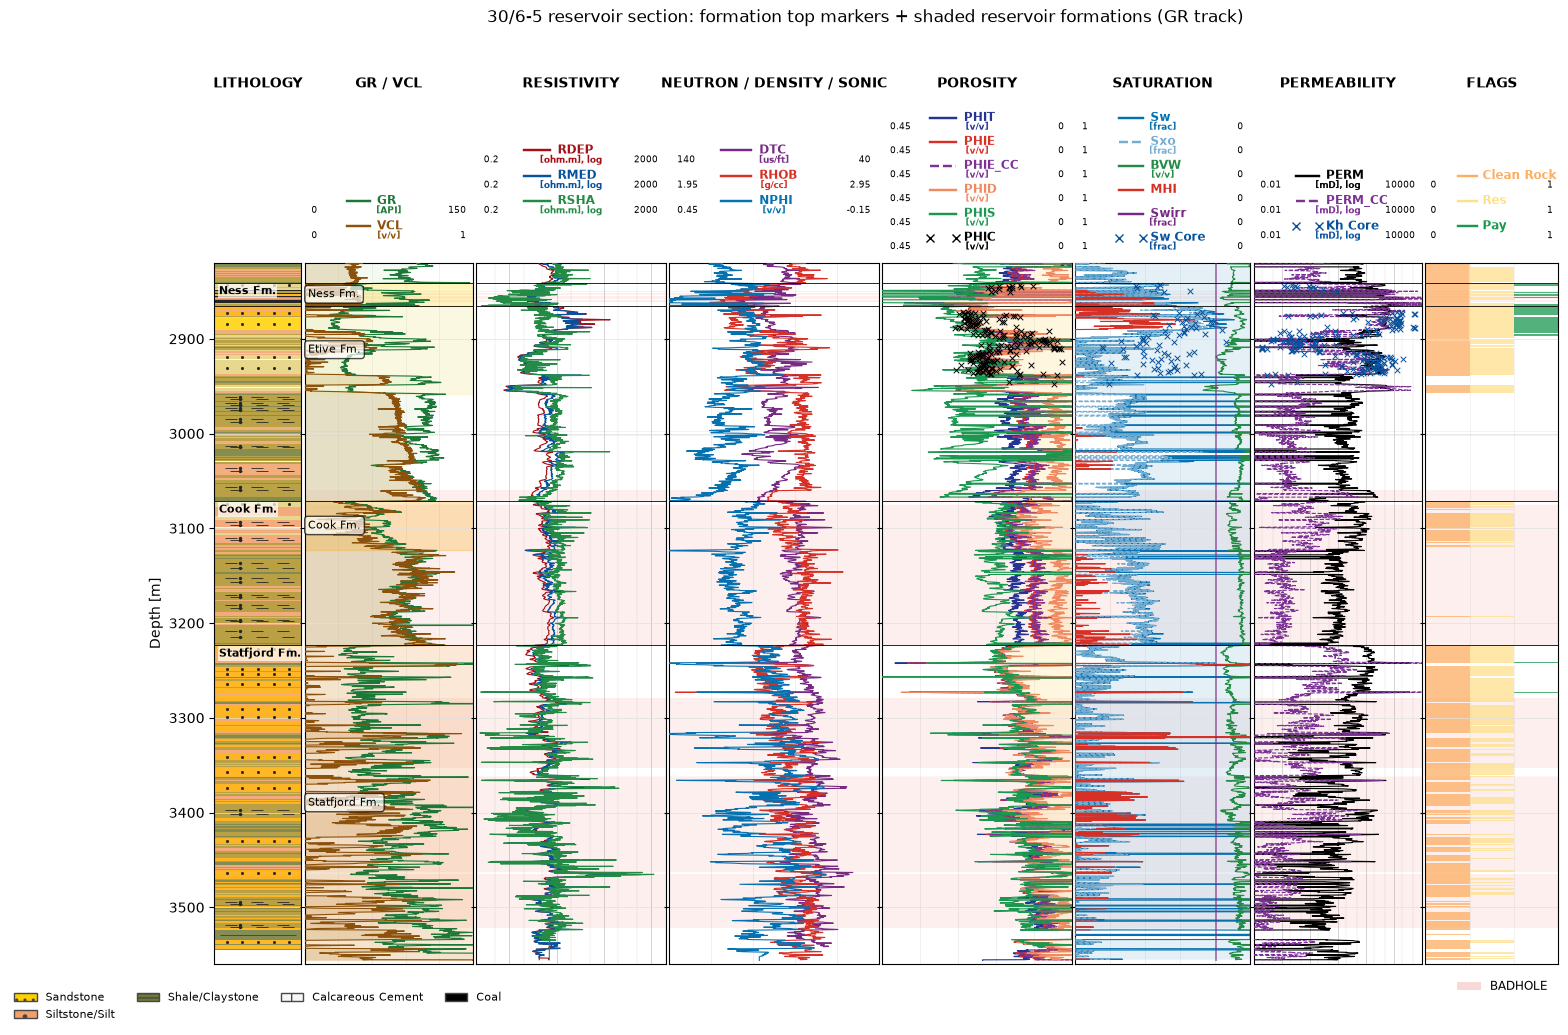

Label diagnostics: [{'name': 'Etive Fm.', 'depth': 2865.0, 'reason': 'label spacing'}]


In [13]:
from petrophys.visualization import create_log_viewer

reservoir_fms = ["Ness Fm.", "Etive Fm.", "Cook Fm.", "Statfjord Fm."]
palette = {"Ness Fm.":"gold", "Etive Fm.":"khaki",
           "Cook Fm.":"orange", "Statfjord Fm.":"sandybrown"}
shade = []
for name in reservoir_fms:
    iv = tops.get_by_name(name)
    if iv is not None:
        shade.append({"top": iv.top_depth, "bottom": iv.bottom_depth,
                      "name": iv.name, "color": palette[name]})

top_d, bot_d = 2820.0, 3560.0   # window covers all four shaded formations

# The "petrophysics" template renders GR, PHIE (POROSITY track) and the NET_PAY
# flag track. formation_tops= draws the named top MARKERS over every track;
# the actual colored shading is added below with add_zone_shading.
viewer = result.plot(
    template_defaults="petrophysics",
    depth_range=(top_d, bot_d),
    formation_tops=shade,
    figsize=(14, 10),
)

# Real colored spans on the GR/VCL track: locate its data axis via the track
# header title, then paint the four reservoir formations.
gr_ax = next(ax for hax, ax in zip(viewer.header_axes, viewer.axes)
             if hax.texts and hax.texts[0].get_text().startswith("GR"))
add_zone_shading(gr_ax, shade, alpha=0.25)

_ = viewer.fig.suptitle(
    "30/6-5 reservoir section: formation top markers + shaded reservoir "
    "formations (GR track)", y=1.0)
viewer.show()
viewer.close()
print("Label diagnostics:", viewer.diagnostics["suppressed_formation_labels"])


The horizontal lines are formation tops; colored spans on the GR/VCL track are explicit zone shading. Coincident names are retained. Labels can still be suppressed when the window is crowded; inspect `viewer.diagnostics["suppressed_formation_labels"]` rather than assuming an unlabelled boundary was absent from the input.

## Pitfalls and parameter choices

- Supply or verify depth units, reference and datum. Compatible length units can be converted; MD/TVD and datum changes need real transformations.
- Missing metadata is a recorded assumption, not verified alignment.
- Declared rank/parent containment differs from an unlabelled overlap or a midpoint-derived parent label.
- The shared formation-summary API uses union totals. Do not manually add overlapping row totals.
- Use explicit final bottoms or terminal depths for top-only analysis.
- Legacy IntervalAnalyzer/single-zone summaries are useful per interval, but their row sums are not hierarchy-aware union totals.
- Pay-weighted averages and the HCPV thickness index are not whole-interval statistics or volumetric OOIP.

## Recap

- `FormationTops.from_csv` / `from_dataframe` load and query the interval
  geometry; the `Formation`/`Zone`/`SubZone` classes model the hierarchy.
- `IntervalAnalyzer` (and `analyze_interval`) give per-interval net pay, NTG,
  averages, dominant lithology, and coverage.
- `summarize_zones` rolls up an explicit zone list; `run_formation_analysis`
  is the end-to-end LAS -> workflow -> per-formation report.
- `add_zone_shading` paints named formation spans behind any depth track;
  `create_log_viewer(formation_tops=...)` draws top markers only.

## Try it yourself

> **Exercise 1.** Load the lithology CSV as `IntervalKind.ZONE` and run
> `IntervalAnalyzer.analyze_all` on it. Compare net pay bucketed by *lithology*
> against the formation buckets.
>
> **Exercise 2.** Add `Draupne Fm.` (a source-rock shale) to the shaded plot and
> confirm its NTG is ~0.
>
> **Exercise 3.** Re-run `run_formation_analysis` with `sw_cutoff=0.5` and
> compare total net pay against the base run - which formations lose the most?

## What's next

Continue to core calibration and sensitivity checks before treating any interval summary as decision-ready. For file mapping, templates and error handling, revisit [Your Own Data](../own_data.ipynb). Formation/lithology inputs remain optional for the underlying interpretation workflow.